<a href="https://colab.research.google.com/github/alyanabilapu/AnalyticsEngineering/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [5]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os
import shutil

import duckdb
import pandas as pd

DATA_URL = "/content/bike_hire_student"
DATA_DIR = "/content/bikes"

# Download only if no CSV files are there yet.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    os.makedirs(DATA_DIR, exist_ok=True)
    # Check if the DATA_URL is actually a local directory or file
    if os.path.exists(DATA_URL):
        if os.path.isdir(DATA_URL):
            # Copy contents if it's a directory
            for item in os.listdir(DATA_URL):
                s = os.path.join(DATA_URL, item)
                d = os.path.join(DATA_DIR, item)
                if os.path.isdir(s):
                    shutil.copytree(s, d, dirs_exist_ok=True)
                else:
                    shutil.copy2(s, d)
        elif DATA_URL.endswith(".zip"):
            import zipfile
            zipfile.ZipFile(DATA_URL).extractall(DATA_DIR)
    else:
        # Fallback to downloading if it looks like a URL
        import urllib.request
        import zipfile
        urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
        zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))

trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [ ]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))

display(q("SELECT * FROM bikes LIMIT 5"))

display(q("SELECT * FROM stations LIMIT 5"))

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,electric,2024
3,B004,Standard,2021
4,B005,STANDARD,2022


,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0
3,S04,University Gate,West,28.0
4,S05,Park Road,South,22.0


In [ ]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

There are 3 tables to look at which is trips, bikes, and stations. First we need to look at the structure of the table and what each row represents:


1. `trips`, each row represents one complete trip, recording the start station, end station, start time, trip duration, and user type. From this table I will use `trips.trip_id`,`trips.bike_id`, `trips.start_station_id`, and `trips.duration_min`.

From the simple statistics summary python code has generated, we can see that:
*  `trips` table has 612 entries, but in colums `trips.duration_min` has only 582 entries, which means **there are 30 empty data points.**
*   Checking the dupplicates, there are **12 data points** are exactly the same in the table **(duplicates)**.
* The max value from column `trips.duration_min` is **2880 min (outlier)**, which is around 48 hrs. This too far from it's median and 75% quartile.

2. `bikes`, each row represents o a single bike. It includes the bike's unique identifier, its type, and the year it was purchased by the company. From this table I will use `bikes.bike_id` and `bikes.bike_type`.

The `bikes` table has 60 entries, with no NULL values, no `bikes.bike_id` duplicate values. We can infer the table is good to go.

3. `stations`, each row represents one station and records its name, the zone where it is located, and its capacity. From this table I will use `stations.station_id` and `stations.zone`.

The `stations` tables has 12 entries, with no duplicated values. But from the Python summary generated, it shows that in column `stations.capacity` **it has 1 NULL values.**








In [24]:
import pandas as pd

trips = pd.read_csv('/content/bike_hire_student/trips.csv')
bikes = pd.read_csv('/content/bike_hire_student/bikes.csv')
stations = pd.read_csv('/content/bike_hire_student/stations.csv')

trips.info()
print(trips.duplicated().sum())
print(trips.isnull().sum())
print("Number of duplicated rows in trips:", trips.duplicated().sum())
print(trips.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trip_id           612 non-null    object 
 1   bike_id           612 non-null    object 
 2   start_station_id  612 non-null    object 
 3   end_station_id    612 non-null    object 
 4   start_time        612 non-null    object 
 5   duration_min      582 non-null    float64
 6   user_type         612 non-null    object 
dtypes: float64(1), object(6)
memory usage: 33.6+ KB
12
trip_id              0
bike_id              0
start_station_id     0
end_station_id       0
start_time           0
duration_min        30
user_type            0
dtype: int64
Number of duplicated rows in trips: 12
       duration_min
count    582.000000
mean      27.891753
std      145.064305
min        4.000000
25%       12.000000
50%       16.000000
75%       22.000000
max     2880.000000


In [29]:
bikes.info()
print(bikes.duplicated().sum())
print(bikes.isnull().sum())
print("Number of duplicated rows in bikes:", bikes.duplicated().sum())
print(bikes.describe())
print(bikes.bike_id.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   bike_id        60 non-null     object
 1   bike_type      60 non-null     object
 2   purchase_year  60 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.5+ KB
0
bike_id          0
bike_type        0
purchase_year    0
dtype: int64
Number of duplicated rows in bikes: 0
       purchase_year
count      60.000000
mean     2022.550000
std         1.185005
min      2021.000000
25%      2021.000000
50%      2023.000000
75%      2024.000000
max      2024.000000
0


In [31]:
stations.info()
print(stations.duplicated().sum())
print(stations.isnull().sum())
print("Number of duplicated rows in stations:", stations.duplicated().sum())
print(stations.describe())
print(stations.station_name.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    12 non-null     object 
 1   station_name  12 non-null     object 
 2   zone          12 non-null     object 
 3   capacity      11 non-null     float64
dtypes: float64(1), object(3)
memory usage: 516.0+ bytes
0
station_id      0
station_name    0
zone            0
capacity        1
dtype: int64
Number of duplicated rows in stations: 0
        capacity
count  11.000000
mean   22.909091
std     5.539938
min    14.000000
25%    19.000000
50%    24.000000
75%    27.500000
max    29.000000
0


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

**'TRIPS' TABLE CLEAN AND PREPARE**
1. From the previous task we know there's 12 duplicates row in the `trips` tables. We should drop the duplicates, keeping one row only.
2. We should standardise the `trips.user_type` way of formatting, there's inconsistent case usage.
3. Get rid of the outlier so it won't ruin the statistics result.

In [68]:
# Reset trips from the tables dictionary to ensure it is a proper DataFrame
trips = tables["trips"].copy()

# To check the duplicated data
duplicated_rows = trips[trips.duplicated(keep=False)]
display(duplicated_rows)

# To drop duplicates
trips = trips.drop_duplicates(keep='first')
display(trips) # Check if rows have decreased by the number of duplicates

# Standardise user_type casing
trips["user_type"] = trips["user_type"].str.strip().str.title()
print(trips["user_type"].value_counts())

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
96,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
97,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
175,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
176,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
185,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
186,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
285,T0283,B014,S07,S04,2025-03-15 19:48:00,5.0,Member
286,T0283,B014,S07,S04,2025-03-15 19:48:00,5.0,Member
326,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member
327,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member
...,...,...,...,...,...,...,...
607,T0596,B051,S02,S02,2025-03-31 13:51:00,NaN,Casual
608,T0597,B011,S01,S04,2025-03-31 14:00:00,19.0,Member
609,T0598,B046,S06,S11,2025-03-31 15:38:00,12.0,Member
610,T0599,B027,S04,S02,31/03/2025 18:38,21.0,casual


user_type
Member    386
Casual    214
Name: count, dtype: int64


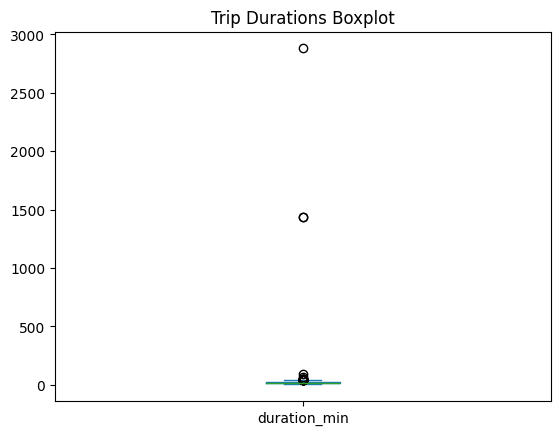

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
80,T0081,B010,S12,S11,2025-03-04 21:57:00,2880.0,Member
143,T0143,B020,S09,S10,2025-03-08 12:23:00,1440.0,Casual
287,T0284,B046,S08,S03,2025-03-15 20:25:00,1440.0,Member


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,Casual
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member
...,...,...,...,...,...,...,...
607,T0596,B051,S02,S02,2025-03-31 13:51:00,NaN,Casual
608,T0597,B011,S01,S04,2025-03-31 14:00:00,19.0,Member
609,T0598,B046,S06,S11,2025-03-31 15:38:00,12.0,Member
610,T0599,B027,S04,S02,31/03/2025 18:38,21.0,Casual


In [77]:
# Kolom durasi, ada outlier 2880 mins, pake boxplot ada 3 data point yang jauh banget.
import matplotlib.pyplot as plt

# Reset trips to ensure we have the correct DataFrame
trips = tables["trips"].copy()
trips = trips.drop_duplicates(keep='first')
trips["user_type"] = trips["user_type"].str.strip().str.title()

trips["duration_min"].plot(kind="box")
plt.title("Trip Durations Boxplot")
plt.show()

# Melihat mana saja yang outlier (> 120 menit)
display(trips[trips["duration_min"] > 120])

# Memfilter outlier: simpan durasi <= 180 ATAU yang nilainya kosong (null)
trips = trips[(trips["duration_min"] <= 180) | (trips["duration_min"].isna())]
display(trips)

In [84]:
#menghapus NaN di kolom durasi
trips = trips[(trips["duration_min"]).notna()]

#standarisasi penulisan date di kolom start_time
iso = pd.to_datetime(trips["start_time"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
slash = pd.to_datetime(trips["start_time"], format="%d/%m/%Y %H:%M", errors="coerce")

trips["start_time"] = iso.fillna(slash)

display(trips)

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,Casual
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member
...,...,...,...,...,...,...,...
606,T0595,B060,S02,S02,2025-03-31 13:26:00,12.0,Casual
608,T0597,B011,S01,S04,2025-03-31 14:00:00,19.0,Member
609,T0598,B046,S06,S11,2025-03-31 15:38:00,12.0,Member
610,T0599,B027,S04,S02,2025-03-31 18:38:00,21.0,Casual


**'BIKES' TABLE CLEAN AND PREPARE**
1. Standardize the spelling and capitalization of `bike_type`.
2. Found one record labeled “e-bike” instead of “Electric” and replaced it so both refer to the same category.

In [100]:
# Reset bikes to ensure we have the correct DataFrame
bikes["bike_type"] = bikes["bike_type"].str.strip().str.title()
bikes["bike_type"] = bikes["bike_type"].str.replace("E-Bike", "Electric")
display(bikes.head())

print(bikes["bike_type"].value_counts())

,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,Electric,2024
3,B004,Standard,2021
4,B005,Standard,2022


bike_type
Standard    47
Electric    13
Name: count, dtype: int64


**'STATIONS' TABLE CLEAN AND PREPARE**
1. The only problem in this table is the missing values for S09, but removing it won't do any better because it's an important information row. Option is to **just flag it during the analysis process** or change it with **Centre Zone's mean**.

In [101]:
display(stations)

,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0
3,S04,University Gate,West,28.0
4,S05,Park Road,South,22.0
5,S06,Library Corner,Centre,26.0
6,S07,Hospital Entrance,East,27.0
7,S08,Riverside Walk,South,14.0
8,S09,Old Town Hall,Centre,NaN
9,S10,Retail Park,North,16.0


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

**GOAL:** One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

## 6. What I could not verify

*What remains unchecked? What would you do next?*